# Arabica + robusta: model search and a three-mixture classifier

**Data:** `arabica_robusta_out/training_samples.csv` (from `arabica_robusta_reflectance_samples.ipynb`), labels exactly
as given in the sample list. Target: **robusta %** (0–50). Test samples J, K, L are left out.

| Session | Scan set | Dishes (strip → bottom) | Robusta % |
|---|---|---|---|
| 1 | 4 Sep ~12:00 | AR 50-50, AR 60-40, AR 70-30 | 50, 40, 30 |
| 2 | 4 Sep ~13:30 | AR 80-20, AR 90-10, AR 50-50, AR 100 | 20, 10, 50, 0 |
| 3 | 7 Sep | AR 55-45, 65-35, 75-25, 85-15, 95-05 | 45, 35, 25, 15, 5 |

The label check in `arabica_robusta_reflectance_samples.ipynb` found the spectra disagree with these labels. So this
notebook first asks whether the spectra follow the labels *inside a single scan set* (section 2), where no day-to-day
change can interfere, before comparing models (section 3) and building the three-mixture classifier (section 4).

Same protocol and building blocks as the robusta and arabica models (executed from `robusta_chicory_nested_loso.ipynb`):
absorbance + offset on 1000–2450 nm, trimming and super-patches rebuilt inside each round, inner leave-one-level-out
with the one-standard-error rule, error per dish on the held-out session. Outputs: `arabica_robusta_models/`.

## 1. Data and building blocks

In [1]:
import os
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.stats import spearmanr

SRC = Path(os.environ.get("COFFEE_DATA", ".")) / "robusta_chicory_nested_loso.ipynb"
_nb = json.loads(SRC.read_text()); _cell = lambda i: "".join(_nb["cells"][i]["source"])
exec(_cell(2), globals())                     # imports, constants, plot style (BASE, WL_MIN/MAX, TRIM_PCT, K_UNIT, ...)
OUT = BASE / "arabica_robusta_models"; OUT.mkdir(exist_ok=True, parents=True)

AR = pd.read_csv(BASE / "arabica_robusta_out" / "training_samples.csv")
DATA = AR[AR.role == "calibration"].reset_index(drop=True)
DATA["session"] = DATA["day"].astype(int)
DATA["chicory_pct"] = DATA["robusta_pct"]     # the shared building blocks read the target from this column: here it is ROBUSTA %
wc = [c for c in DATA.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc]); BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]

def preprocess(R):
    Z = np.log10(1.0 / np.clip(np.asarray(R, float), 1e-3, None))
    return Z - Z.mean(-1, keepdims=True)

Z = preprocess(DATA[COLS].values)
SESSION, GROUP, Y = DATA["session"].to_numpy(), DATA["group"].astype(str).to_numpy(), DATA["chicory_pct"].to_numpy(float)
exec(_cell(6), globals())                     # units(), make(), GRIDS, tune(), predict(), score(): unchanged
print(f"{len(DATA)} patches | {DATA.group.nunique()} dishes | sessions {sorted(DATA.session.unique())}")
print(DATA.groupby(["session", "label"]).agg(robusta=("robusta_pct", "first"), dishes=("group", "nunique")).to_string())

5390 patches | 36 dishes | sessions [np.int64(1), np.int64(2), np.int64(3)]
                   robusta  dishes
session label                     
1       AR[50:50]     50.0       3
        AR[60:40]     40.0       3
        AR[70:30]     30.0       3
2       AR100          0.0       3
        AR[50:50]     50.0       3
        AR[80:20]     20.0       3
        AR[90:10]     10.0       3
3       AR[55:45]     45.0       3
        AR[65:35]     35.0       3
        AR[75:25]     25.0       3
        AR[85:15]     15.0       3
        AR[95:5]       5.0       3


## 2. Do the spectra follow the labels inside one scan set?

Inside a single scan set every dish shares the lamp, the white strip and the day, so if the labels are right, a
simple model must rank the dishes by robusta %. Each level is left out in turn and predicted from the other levels
of **the same scan set** (PLSR, 1–3 components). Also shown: the 2310 nm coffee-oil band depth, which drops with
chicory but should stay roughly constant in a pure arabica–robusta blend (both coffees are oily).

In [2]:
from sklearn.cross_decomposition import PLSRegression
rows = []
for s in (1, 2, 3):
    ZU, UM = units([s]); m = (UM.session == s).to_numpy()
    X, y, g = ZU[m], UM.chicory_pct[m].to_numpy(float), UM.group[m].to_numpy()
    for a in (1, 2, 3):
        p = np.full(len(y), np.nan)
        for lev in np.unique(y):
            te = y == lev
            p[te] = PLSRegression(a).fit(X[~te], y[~te]).predict(X[te]).ravel()
        d = pd.DataFrame(dict(y=y, p=p, g=g)).groupby("g")[["y", "p"]].mean().groupby("y").p.mean()
        rows.append(dict(session=s, components=a, **{f"{int(k)} %": round(v, 1) for k, v in d.items()},
                         spearman=round(float(spearmanr(d.index, d.values).statistic), 2)))
WITHIN = pd.DataFrame(rows)
print("leave-one-level-out INSIDE each scan set: predicted robusta % per labelled level")
print(WITHIN.to_string(index=False))

i = lambda x: int(np.argmin(abs(wl_all - x)))
dish = DATA.groupby(["session", "label", "group"])[wc].mean()
R = dish.to_numpy()
cont = R[:, i(2270)] + (R[:, i(2380)] - R[:, i(2270)]) * (wl_all[i(2310)] - wl_all[i(2270)]) / (wl_all[i(2380)] - wl_all[i(2270)])
band = pd.Series(1 - R[:, i(2310)] / cont, index=dish.index).groupby(level=[0, 1]).mean().round(4)
print("\n2310 nm coffee-oil band depth per dish type (pure coffees on 1 Sep: arabica 0.095, robusta 0.085, chicory 0.024):")
print(band.to_string())

leave-one-level-out INSIDE each scan set: predicted robusta % per labelled level
 session  components  30 %  40 %  50 %  spearman  0 %   10 %  20 %  5 %  15 %  25 %  35 %  45 %
       1           1  41.6  35.4  41.3      -0.5  NaN    NaN   NaN  NaN   NaN   NaN   NaN   NaN
       1           2  37.2  41.1  44.0       1.0  NaN    NaN   NaN  NaN   NaN   NaN   NaN   NaN
       1           3  36.6  41.4  44.1       1.0  NaN    NaN   NaN  NaN   NaN   NaN   NaN   NaN
       2           1   NaN   NaN   1.3      -0.8 45.1   11.9  15.8  NaN   NaN   NaN   NaN   NaN
       2           2   NaN   NaN   0.9      -0.4 46.6  -53.1  30.1  NaN   NaN   NaN   NaN   NaN
       2           3   NaN   NaN   1.4       0.0 47.7 -103.5  81.7  NaN   NaN   NaN   NaN   NaN
       3           1   NaN   NaN   NaN       1.0  NaN    NaN   NaN 10.1  19.4  23.6  33.3  40.7
       3           2   NaN   NaN   NaN       1.0  NaN    NaN   NaN  9.2  18.2  22.5  33.9  44.9
       3           3   NaN   NaN   NaN       1.0  NaN  

## 3. Model search: nested leave-one-session-out

Three sessions, so three rounds, each scan set predicted by models trained on the other two. Eleven candidates: the
eight standard methods on absorbance + offset, EMSC + PLSR, first derivative + PLSR, and first derivative + PLSR on
the chemistry bands only (1650–1800 and 2150–2400 nm, the arabica-vs-robusta regions found from the matched pairs).

In [3]:
LAM = np.linspace(-1, 1, len(WL))
def emsc(ZU, tr, y):
    m = ZU[tr].mean(0); yc = y[tr] - y[tr].mean(); k = yc @ (ZU[tr] - m) / (yc @ yc)
    B = np.column_stack([np.ones_like(LAM), m, k, LAM, LAM ** 2])
    a, b, h, d, e = np.linalg.lstsq(B, ZU.T, rcond=None)[0]
    return (ZU - a[:, None] - np.outer(d, LAM) - np.outer(e, LAM ** 2)) / b[:, None]

Z_STD = Z.copy()
Z_SG1 = savgol_filter(np.log10(1.0 / np.clip(DATA[COLS].values.astype(float), 1e-3, None)), 15, 2, deriv=1, axis=1)
OUTER, PRED = [], []
CHEM = ((WL >= 1650) & (WL <= 1800)) | ((WL >= 2150) & (WL <= 2400))
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    for variant, Zv in (("std", Z_STD), ("sg1", Z_SG1), ("chem", Z_SG1[:, CHEM])):
        Z = Zv; _UNITS.clear()
        ZU, UM = units(train)
        us, y, g = UM.session.to_numpy(), UM.chicory_pct.to_numpy(float), UM.group.to_numpy()
        tr, te = np.isin(us, train), us == held
        jobs = {"std": list(GRIDS) + ["EMSC + PLSR"], "sg1": ["first derivative + PLSR"], "chem": ["chemistry bands, derivative + PLSR"]}[variant]
        for name in jobs:
            X = emsc(ZU, tr, y) if name.startswith("EMSC") else ZU
            base = "PLSR" if "PLSR" in name else name
            prm, _ = tune(base, X[tr], y[tr], g[tr])
            p = predict(make(base, prm).fit(X[tr], y[tr]), X[te])
            d = UM.loc[te, ["session", "label", "group"]].assign(y=y[te], p=p, model=name, fold=held)
            PRED.append(d); OUTER.append(dict(model=name, held_out=held, param=prm, **score(d)))
Z = Z_STD; _UNITS.clear()
OUTER = pd.DataFrame(OUTER); PRED = pd.concat(PRED, ignore_index=True)
SUM = OUTER.pivot(index="model", columns="held_out", values="rmsep_plate").rename(columns=lambda s: f"S{s} held out")
SUM["mean"] = SUM.mean(1)
SUM["bias S1 / S2"] = OUTER.pivot(index="model", columns="held_out", values="bias").round(1).astype(str).agg(" / ".join, axis=1)
SUM = SUM.sort_values("mean")
print("plate RMSEP on the held-out scan set (% robusta):")
print(SUM.round(2).to_string())
best = SUM.index[0]
print(f"\nlowest: {best}. Predicted vs labelled robusta % (held-out dishes, mean per dish type):")
print(PRED[PRED.model == best].groupby(["fold", "label", "y"]).p.mean().round(1).to_string())
SUM.to_csv(OUT / "model_summary.csv"); PRED.to_csv(OUT / "heldout_predictions.csv", index=False)

plate RMSEP on the held-out scan set (% robusta):
held_out                            S1 held out  S2 held out  S3 held out   mean         bias S1 / S2
model                                                                                                
SVR (linear)                               1.98        25.56         2.96  10.16   -1.7 / -12.7 / 2.3
Gradient Boosting                          5.67        22.18         3.14  10.33    -3.4 / -6.2 / 0.0
Random Forest                              4.29        22.68         4.37  10.45    -2.2 / -7.9 / 2.4
SVR (RBF)                                  6.10        19.71         8.69  11.50     -4.3 / 1.7 / 5.3
first derivative + PLSR                    4.12        24.37         7.47  11.99   -3.3 / -11.1 / 5.3
chemistry bands, derivative + PLSR         4.12        24.97         7.27  12.12   -3.2 / -12.7 / 5.4
ElasticNet                                 8.69        24.84         9.10  14.21   -8.4 / -12.0 / 7.0
Ridge                           

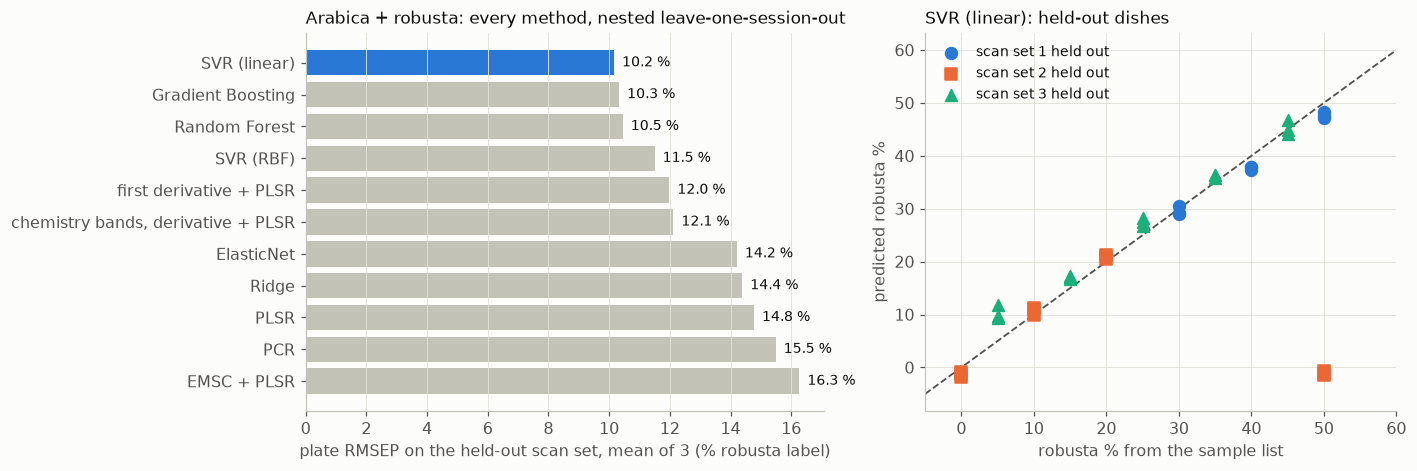

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axs[0]
order = SUM.index.tolist()
ax.barh(range(len(order)), SUM["mean"], color=[HIGHLIGHT if m == best else OTHER for m in order])
for k, v in enumerate(SUM["mean"]): ax.text(v, k, f"  {v:.1f} %", va="center", fontsize=9)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("plate RMSEP on the held-out scan set, mean of 3 (% robusta label)")
ax.set_title("Arabica + robusta: every method, nested leave-one-session-out", loc="left", fontsize=11)
ax = axs[1]
sel = PRED[PRED.model == best].groupby(["fold", "group", "y"], as_index=False).p.mean()
for s in (1, 2, 3):
    q = sel[sel.fold == s]
    ax.scatter(q.y, q.p, s=60, color=S_COLOR[s], marker=S_MARKER[s], label=f"scan set {s} held out", zorder=3)
ax.plot([-5, 60], [-5, 60], ls="--", color=INK2, lw=1.2)
ax.set_xlim(-5, 60); ax.set_xlabel("robusta % from the sample list"); ax.set_ylabel("predicted robusta %")
ax.set_title(f"{best}: held-out dishes", loc="left", fontsize=11); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(OUT / "01_model_search.png", bbox_inches="tight"); plt.show()

## 4. Three-mixture classifier

Classes: robusta + chicory (33 dishes, 3 sessions), arabica + chicory (33 dishes, 3 sessions), arabica + robusta (21
dishes, 2 scan sets). PLS-DA on absorbance + offset super-patches, dish = mean output, class = largest output.
Validation: **leave one scan set out** (8 scan sets), so every dish is classified by a model that never saw its scan.

In [5]:
_ns = {}
exec(open(BASE / "coffee_app" / "train_app_models.py").read().split("fam = {}")[0], _ns)   # load(), units() of the app models
FAM = {}
for F in ("RBCH", "ABCH"):
    D = _ns["load"](F); Zf = _ns["preprocess"](D[_ns["COLS"]].values)
    ZU, UM, _ = _ns["units"](D, Zf); FAM[F] = (ZU, UM.assign(scanset=[f"{F}-S{s}" for s in UM.session]))
Dar = DATA.copy()
ZU, UM, _ = _ns["units"](Dar, _ns["preprocess"](Dar[_ns["COLS"]].values)); FAM["ARRB"] = (ZU, UM.assign(scanset=[f"ARRB-S{s}" for s in UM.session]))
CL = ["RBCH", "ABCH", "ARRB"]
X = np.vstack([FAM[F][0] for F in CL])
M = pd.concat([FAM[F][1].assign(cls=F) for F in CL], ignore_index=True)
Yc = np.column_stack([(M.cls == F).to_numpy(float) for F in CL])
res = []
for a in (2, 3, 4, 5, 6, 8, 10, 12):
    pred = {}
    for s_ in M.scanset.unique():
        te = (M.scanset == s_).to_numpy()
        out = PLSRegression(a).fit(X[~te], Yc[~te]).predict(X[te])
        d = pd.DataFrame(out, columns=CL).assign(group=M.group[te].to_numpy(), cls=M.cls[te].to_numpy()).groupby(["group", "cls"]).mean()
        for (gname, c), row in d.iterrows(): pred[gname] = (c, row.idxmax())
    P = pd.DataFrame(pred.values(), columns=["true", "pred"])
    res.append(dict(components=a, correct=int((P.true == P.pred).sum()), dishes=len(P),
                    **{f"{c} correct": f"{int(((P.true == c) & (P.pred == c)).sum())}/{int((P.true == c).sum())}" for c in CL}))
    if a == 4: CONF4 = pd.crosstab(P.true, P.pred)
CLS = pd.DataFrame(res); print(CLS.to_string(index=False))
a_best = int(CLS.loc[CLS.correct.idxmax(), "components"])
print(f"\nconfusion at 4 components (rows = true mixture, columns = predicted):"); print(CONF4.to_string())
CLS.to_csv(OUT / "classifier_validation.csv", index=False)

 components  correct  dishes RBCH correct ABCH correct ARRB correct
          2        4     102         0/33         4/33         0/36
          3       50     102        26/33        13/33        11/36
          4       64     102        27/33        23/33        14/36
          5       70     102        33/33        24/33        13/36
          6       70     102        33/33        23/33        14/36
          8       65     102        33/33        20/33        12/36
         10       57     102        31/33        14/33        12/36
         12       57     102        31/33        17/33         9/36

confusion at 4 components (rows = true mixture, columns = predicted):
pred  ABCH  ARRB  RBCH
true                  
ABCH    23    10     0
ARRB    11    14    11
RBCH     0     6    27


## 5. What is actually varying between the dishes?

Three chemistry checks that do not use the blend labels:

- **`oil2310`**, the 2310 nm coffee-oil band depth (1 Sep: pure arabica 0.095, pure robusta 0.085, pure chicory 0.024). A blend
  of arabica and robusta alone should stay between 0.085 and 0.095.
- **`coffee_score`**, the app's robusta-vs-arabica classifier (pure robusta about −0.2, pure arabica about 1.05; 66/66 correct
  across days on the chicory blends).
- **`RBCH_chicory`** and **`ABCH_chicory`**, the app's two chicory models.

In [6]:
APPM = json.loads((BASE / "coffee_app" / "models.json").read_text())
sel_ = [i for i, w in enumerate(APPM["wavelengths"]) if 1000 <= round(w) <= 2450]; lam_ = np.linspace(-1, 1, len(sel_))
def zz(R):
    z = np.log10(1 / np.clip(np.asarray(R, float)[..., sel_], 1e-3, None)); return z - z.mean(-1, keepdims=True)
def chic(z, F):
    f = APPM["families"][F]
    if "emsc" in f:
        Bm = np.column_stack([np.ones_like(lam_), f["emsc"]["mean"], f["emsc"]["chicory_direction"], lam_, lam_ ** 2])
        a, b, h, d, e = np.linalg.lstsq(Bm, z, rcond=None)[0]; z = (z - a - d * lam_ - e * lam_ ** 2) / b
    return z @ np.array(f["model"]["w"]) + f["model"]["w0"]
iw = lambda x: int(np.argmin(abs(wl_all - x)))
Cc = APPM["classifier"]; rows = []
for (day, lab, grp), dd in AR[AR.role != "unknown"].groupby(["day", "label", "group"]):
    R = dd[wc].values.mean(0); z = zz(dd[wc].values).mean(0)
    cont = R[iw(2270)] + (R[iw(2380)] - R[iw(2270)]) * (wl_all[iw(2310)] - wl_all[iw(2270)]) / (wl_all[iw(2380)] - wl_all[iw(2270)])
    rows.append(dict(session=day, label=lab, robusta_label=dd.robusta_pct.iloc[0], oil2310=1 - R[iw(2310)] / cont,
                     coffee_score=z @ np.array(Cc["w"]) + Cc["w0"], RBCH_chicory=chic(z, "RBCH"), ABCH_chicory=chic(z, "ABCH")))
CHEMCHECK = pd.DataFrame(rows).groupby(["session", "label"]).mean(numeric_only=True).sort_values(["session", "robusta_label"]).round(3)
print(CHEMCHECK.to_string()); CHEMCHECK.to_csv(OUT / "chemistry_checks.csv")
fit = np.polyfit(CHEMCHECK.robusta_label, CHEMCHECK.oil2310, 1)
print(f"\noil band vs labelled robusta %: {fit[1]:.3f} at 0 %, {fit[1] + 100 * fit[0]:.3f} extrapolated to 100 % "
      "(pure robusta 0.085, pure chicory 0.024)")
s3 = CHEMCHECK.loc[3]
print(f"session 3: robusta+chicory model reads the labelled number with RMSE {np.sqrt(((s3.RBCH_chicory - s3.robusta_label) ** 2).mean()):.2f} %")

                   robusta_label  oil2310  coffee_score  RBCH_chicory  ABCH_chicory
session label                                                                      
1       AR[70:30]           30.0    0.064         0.437        28.974        40.732
        AR[60:40]           40.0    0.059         0.514        37.835        48.396
        AR[50:50]           50.0    0.051         0.508        48.546        57.460
2       AR100                0.0    0.084         0.595        -8.359        14.473
        AR[90:10]           10.0    0.080         0.312         3.471        24.306
        AR[80:20]           20.0    0.073         0.539        13.532        32.181
        AR[50:50]           50.0    0.085         0.611        -8.776        14.609
3       AR[95:5]             5.0    0.081         0.532         4.556        19.288
        AR[85:15]           15.0    0.075         0.470        14.178        27.736
        AR[75:25]           25.0    0.067         0.499        24.380       